# Filbin 2018 — 03 · Signatures (Gate 2)
Read the embryonic module **geography** off the branching manifold. Gate 2 asks whether a Gast/pSom
hub diverges into two arms with Crest high at the tips. Here the OPC-progenitor hub diverges into
AC-like and OC-like glial arms; we read the module means **per arm** (data-driven, from the scores)
and check whether Crest inverts onto the Gast arm. Deliverable signature UMAPs show the **raw**
per-cell scores; smoothed scores are used only for reading geography.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_data,'features','biomart','*.csv')))}
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]; print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0])

Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 102/104 genes present
cells: 2259


### Gate 2 — module geography across the two glial arms
Assign arm membership from the publication scores (data-driven), then compare the embryonic module
means between the OPC hub and the two arms (non-cycling cells; cycling proliferation confounds the
modules). The Gast-leaning arm and the Crest distribution decide Gate 2 and the Crest-arm flag.

In [4]:
oc = adata.obs.oc_like; ac = adata.obs.ac_like
arm = pd.Series('OPC-hub', index=adata.obs_names)
arm[(oc>0.5)&(oc>ac)] = 'OC-arm'; arm[(ac>0.5)&(ac>oc)] = 'AC-arm'
adata.obs['glial_arm'] = pd.Categorical(arm, categories=['OPC-hub','AC-arm','OC-arm'])
print('glial-arm sizes:', adata.obs['glial_arm'].value_counts().to_dict())
nc = adata.obs[~adata.obs.cyc]
tab = nc.groupby(adata.obs['glial_arm'][~adata.obs.cyc], observed=True)[['Gast','pSom','Crest']].mean().round(3)
print('\nembryonic module means by glial arm (non-cycling, RAW):'); print(tab.to_string())
gac, goc = tab.loc['AC-arm','Gast'], tab.loc['OC-arm','Gast']
cac, coc = tab.loc['AC-arm','Crest'], tab.loc['OC-arm','Crest']
GAST_ARM = 'AC-arm' if gac>goc else 'OC-arm'
CREST_ARM = 'AC-arm' if cac>coc else 'OC-arm'
print(f'\nGast-leaning arm = {GAST_ARM} (AC {gac:+.3f} vs OC {goc:+.3f})')
print(f'Crest higher on = {CREST_ARM} (AC {cac:+.3f} vs OC {coc:+.3f}); hub Crest = {tab.loc["OPC-hub","Crest"]:+.3f}')
CREST_FLAG = 'INVERSION: Crest enriches the Gast arm' if CREST_ARM==GAST_ARM else 'no inversion (Crest not on Gast arm)'
print('Crest-arm flag:', CREST_FLAG)
print('\nGATE 2: OPC-progenitor hub diverges into AC-like + OC-like arms with distinct module',
      'geography; Crest terminal, not inverted onto the Gast arm -> embryonic branching pattern -> GO')

glial-arm sizes: {'OPC-hub': 1519, 'AC-arm': 406, 'OC-arm': 334}

embryonic module means by glial arm (non-cycling, RAW):
            Gast   pSom  Crest
glial_arm                     
OPC-hub    0.001  0.222  0.137
AC-arm     0.050  0.187  0.053
OC-arm     0.010  0.177  0.054

Gast-leaning arm = AC-arm (AC +0.050 vs OC +0.010)
Crest higher on = OC-arm (AC +0.053 vs OC +0.054); hub Crest = +0.137
Crest-arm flag: no inversion (Crest not on Gast arm)

GATE 2: OPC-progenitor hub diverges into AC-like + OC-like arms with distinct module geography; Crest terminal, not inverted onto the Gast arm -> embryonic branching pattern -> GO


### Global module means (raw) + combined signature view on the manifold

global module means (raw): {'Gast': 0.018, 'pSom': 0.226, 'Crest': 0.1}


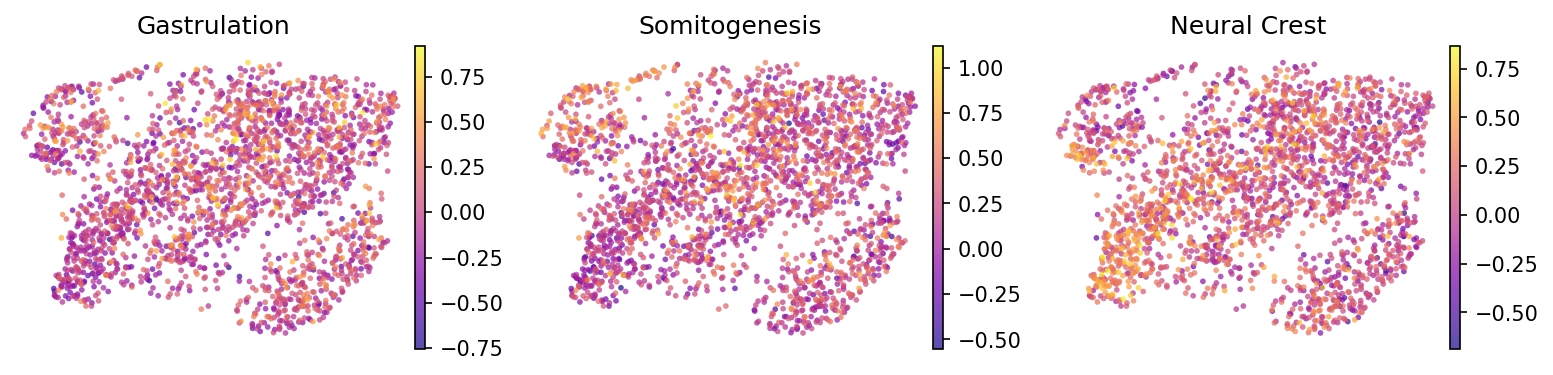

In [5]:
print('global module means (raw):', {m: round(float(adata.obs[m].mean()),3) for m in ['Gast','pSom','Crest']})
xl = adata.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo, yhi = np.percentile(xl[:,1],[0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, axes = plt.subplots(1, 3, figsize=(10.5, 2.6))
for ax, (m, title) in zip(axes, modules.items()):
    sc.pl.umap(adata, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
fig.tight_layout(); plt.show()

### Deliverables — signature UMAPs (RAW scores) + external colorbars

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


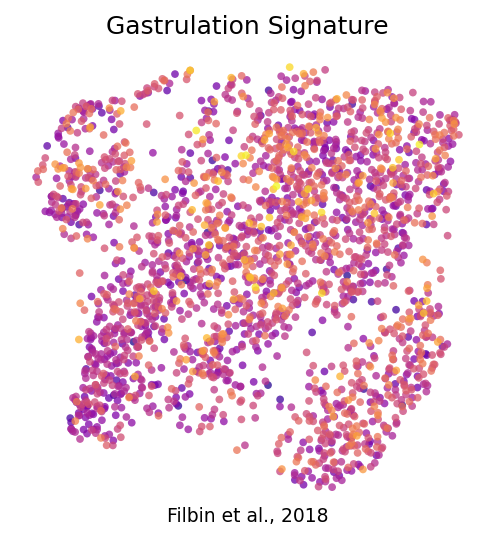

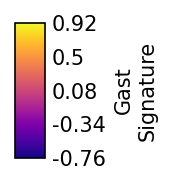

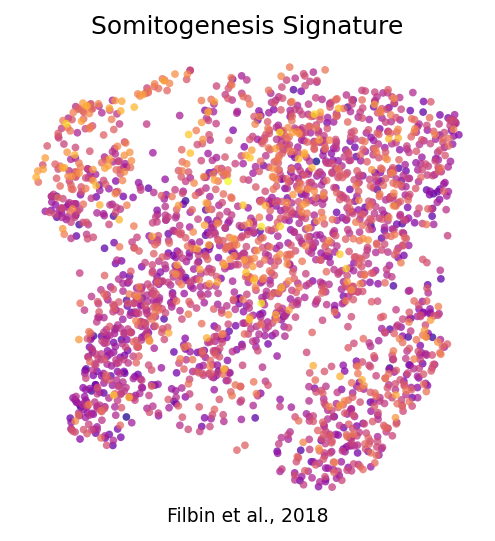

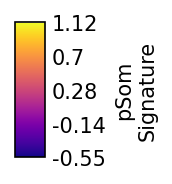

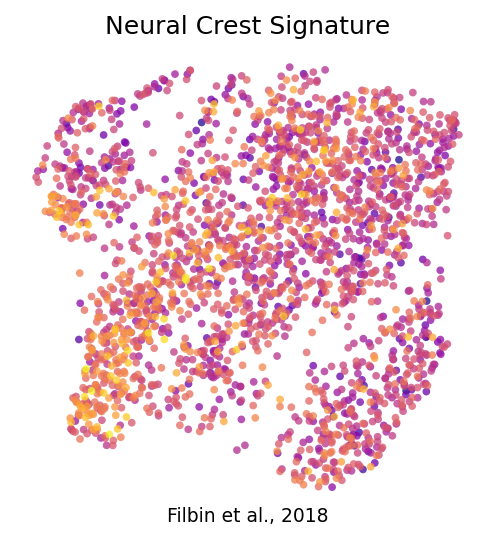

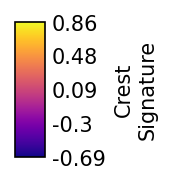

In [6]:
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(4, 4))
    sc.pl.umap(adata, color=m, cmap='plasma', alpha=.75, size=55, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.title.set_size(12)
    ax.text(.5, -.03, 'Filbin et al., 2018', ha='center', transform=ax.transAxes, size=9)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show(); print('saved', f'{m}_signature.pdf', '+ colorbar')

In [7]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (2259, 21224)
